# Modul 3: Zweidimensionale Systeme

---

## Der Sprung in die Ebene

Mit zwei Dimensionen öffnet sich eine neue Welt. In 1D konnten Trajektorien nur vorwärts oder rückwärts. In 2D können sie **umeinander kreisen**.

Das bedeutet:
- Oszillationen werden möglich
- Die Klassifikation der Fixpunkte wird reichhaltiger
- Neue Strukturen erscheinen: Grenzzyklen, Separatrizen, Einzugsgebiete

Aber auch: Der Satz von Poincaré-Bendixson zeigt, dass das Langzeitverhalten in 2D immer noch "zahm" ist - kein Chaos möglich. Dafür braucht es 3D.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import odeint
from scipy.linalg import eig
from mpl_toolkits.mplot3d import Axes3D

plt.rcParams.update({
    'figure.figsize': (12, 10),
    'figure.dpi': 100,
    'axes.labelsize': 14,
    'axes.titlesize': 16,
    'lines.linewidth': 1.5,
})

%matplotlib inline

---

## 3.1 Lineare Systeme als Fundament

Jedes 2D-System kann lokal (um einen Fixpunkt) als lineares System approximiert werden.

$$\begin{pmatrix} \dot{x} \\ \dot{y} \end{pmatrix} = \begin{pmatrix} a & b \\ c & d \end{pmatrix} \begin{pmatrix} x \\ y \end{pmatrix} = A \cdot \mathbf{x}$$

**Fundamentale Einsicht:** Die **Eigenwerte** von $A$ bestimmen vollständig das qualitative Verhalten.

Seien $\lambda_1, \lambda_2$ die Eigenwerte. Die allgemeine Lösung ist:

$$\mathbf{x}(t) = c_1 e^{\lambda_1 t} \mathbf{v}_1 + c_2 e^{\lambda_2 t} \mathbf{v}_2$$

Das Verhalten hängt davon ab, ob die $\lambda$ reell oder komplex sind, und ob ihre Realteile positiv oder negativ sind.

In [2]:
def plot_linear_system(A, x_range=(-3, 3), y_range=(-3, 3), title="", ax=None):
    """
    Visualisiert ein lineares 2D-System ẋ = Ax.
    """
    if ax is None:
        fig, ax = plt.subplots(figsize=(10, 10))
    
    # Berechne Eigenwerte und Eigenvektoren
    eigenvalues, eigenvectors = np.linalg.eig(A)
    
    # Vektorfeld
    x = np.linspace(x_range[0], x_range[1], 20)
    y = np.linspace(y_range[0], y_range[1], 20)
    X, Y = np.meshgrid(x, y)
    
    U = A[0, 0] * X + A[0, 1] * Y
    V = A[1, 0] * X + A[1, 1] * Y
    
    # Normalisiere für Darstellung
    M = np.sqrt(U**2 + V**2)
    M[M == 0] = 1
    
    ax.quiver(X, Y, U/M, V/M, M, cmap='coolwarm', alpha=0.6)
    
    # Trajektorien
    def system(state, t):
        return A @ state
    
    t_forward = np.linspace(0, 5, 500)
    t_backward = np.linspace(0, -5, 500)
    
    # Startpunkte auf einem Kreis
    theta = np.linspace(0, 2*np.pi, 12, endpoint=False)
    r = 2.5
    starts = [[r*np.cos(t), r*np.sin(t)] for t in theta]
    
    for start in starts:
        sol_f = odeint(system, start, t_forward)
        sol_b = odeint(system, start, t_backward)
        
        # Schneide ab, wenn außerhalb
        mask_f = (np.abs(sol_f[:, 0]) < 5) & (np.abs(sol_f[:, 1]) < 5)
        mask_b = (np.abs(sol_b[:, 0]) < 5) & (np.abs(sol_b[:, 1]) < 5)
        
        ax.plot(sol_f[mask_f, 0], sol_f[mask_f, 1], 'b-', alpha=0.7, linewidth=1)
        ax.plot(sol_b[mask_b, 0], sol_b[mask_b, 1], 'b-', alpha=0.7, linewidth=1)
    
    # Eigenvektoren zeichnen (wenn reell)
    if np.isreal(eigenvalues).all():
        for i, (ev, vec) in enumerate(zip(eigenvalues, eigenvectors.T)):
            vec = np.real(vec)
            scale = 2.5
            color = 'green' if np.real(ev) < 0 else 'red'
            ax.arrow(0, 0, scale*vec[0], scale*vec[1], head_width=0.15, 
                    head_length=0.1, fc=color, ec=color, linewidth=2, zorder=5)
            ax.arrow(0, 0, -scale*vec[0], -scale*vec[1], head_width=0.15,
                    head_length=0.1, fc=color, ec=color, linewidth=2, zorder=5)
    
    # Fixpunkt
    ax.plot(0, 0, 'ko', markersize=10, zorder=10)
    
    # Info
    ev_str = ', '.join([f'{e:.2f}' if np.isreal(e) else f'{e:.2f}' for e in eigenvalues])
    ax.set_title(f'{title}\nEigenwerte: {ev_str}', fontsize=14)
    ax.set_xlabel(r'$x$')
    ax.set_ylabel(r'$y$')
    ax.set_xlim(x_range)
    ax.set_ylim(y_range)
    ax.set_aspect('equal')
    ax.axhline(y=0, color='k', linewidth=0.5)
    ax.axvline(x=0, color='k', linewidth=0.5)
    
    return eigenvalues, eigenvectors

---

## 3.2 Die Klassifikation: Der Zoo der Fixpunkte

### Fall 1: Zwei reelle Eigenwerte gleichen Vorzeichens → **Knoten**

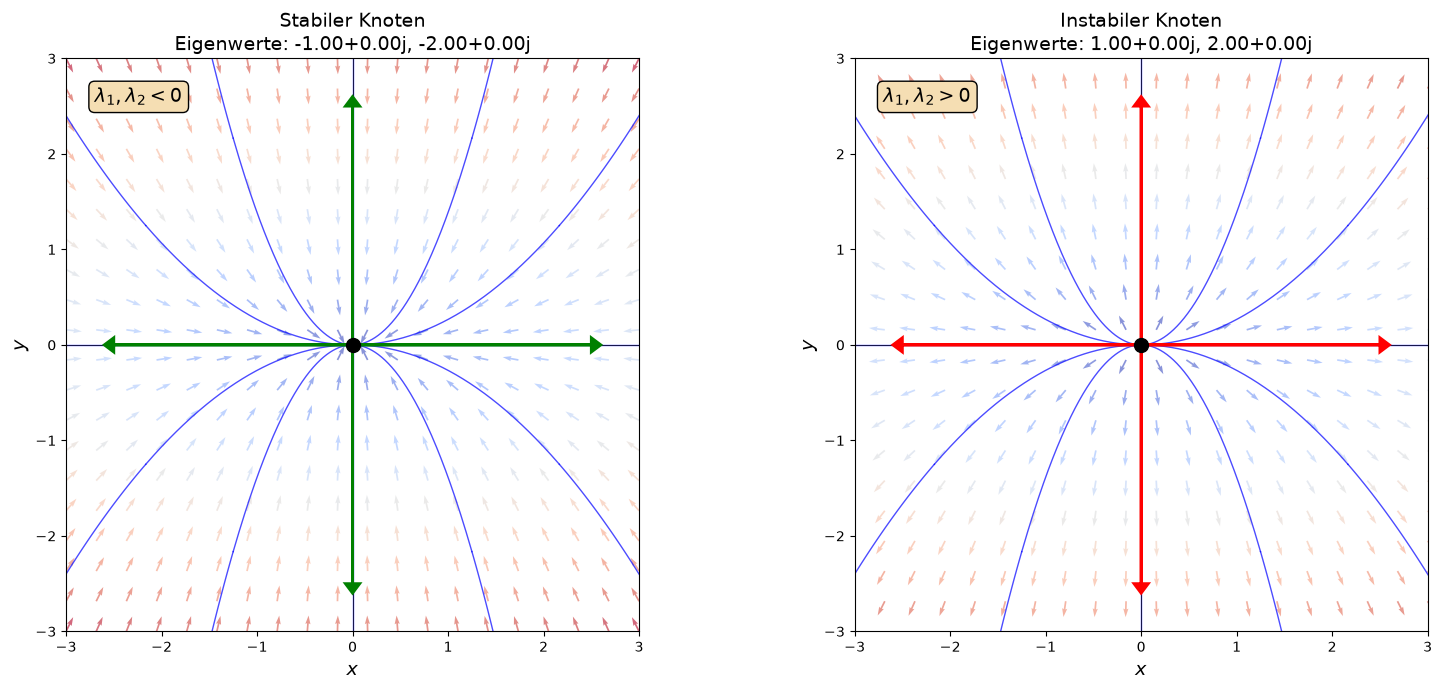

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Stabiler Knoten: λ₁ = -1, λ₂ = -2 (beide negativ)
A_stable_node = np.array([[-1, 0], [0, -2]])
plot_linear_system(A_stable_node, title='Stabiler Knoten', ax=axes[0])
axes[0].text(0.05, 0.95, r'$\lambda_1, \lambda_2 < 0$', transform=axes[0].transAxes,
            fontsize=14, verticalalignment='top', bbox=dict(boxstyle='round', facecolor='wheat'))

# Instabiler Knoten: λ₁ = 1, λ₂ = 2 (beide positiv)
A_unstable_node = np.array([[1, 0], [0, 2]])
plot_linear_system(A_unstable_node, title='Instabiler Knoten', ax=axes[1])
axes[1].text(0.05, 0.95, r'$\lambda_1, \lambda_2 > 0$', transform=axes[1].transAxes,
            fontsize=14, verticalalignment='top', bbox=dict(boxstyle='round', facecolor='wheat'))

plt.tight_layout()
plt.show()

### Beobachtungen bei Knoten

- **Stabiler Knoten**: Alle Trajektorien laufen zum Ursprung
- **Instabiler Knoten**: Alle Trajektorien fliehen vom Ursprung
- Die Trajektorien sind **tangential zur Eigenrichtung des betragskleineren Eigenwerts** (die "langsame" Richtung)

Die grünen Pfeile zeigen die stabilen Eigenrichtungen, die roten die instabilen.

### Fall 2: Reelle Eigenwerte verschiedenen Vorzeichens → **Sattelpunkt**

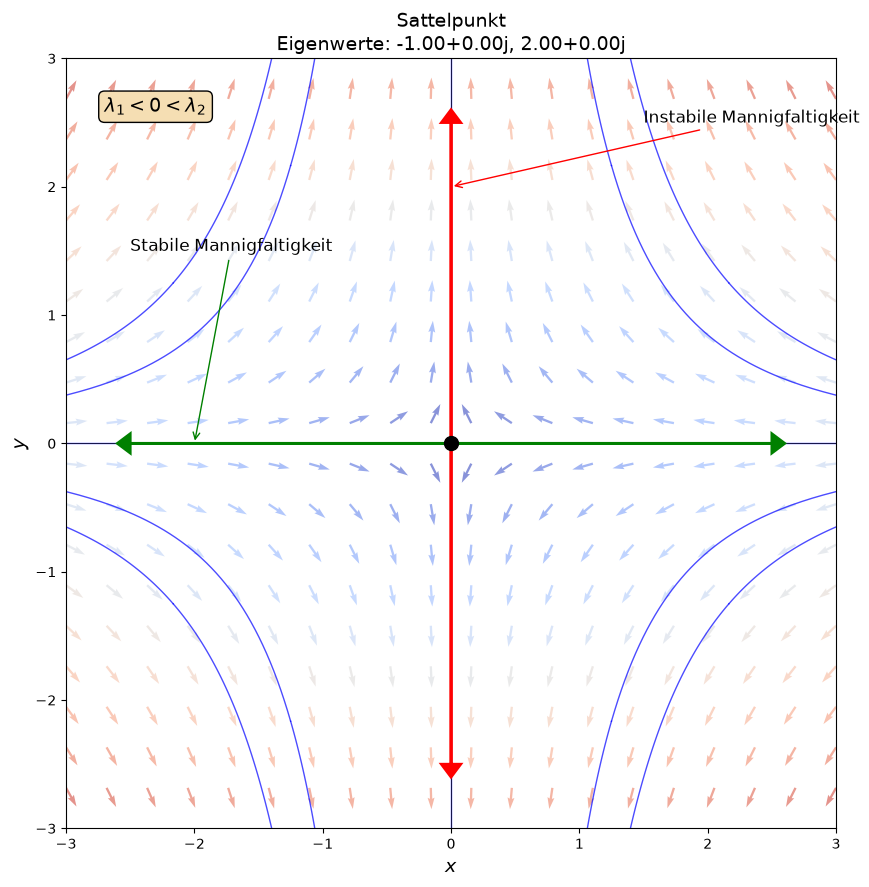

In [4]:
fig, ax = plt.subplots(figsize=(10, 10))

# Sattelpunkt: λ₁ = -1, λ₂ = 2
A_saddle = np.array([[-1, 0], [0, 2]])
plot_linear_system(A_saddle, title='Sattelpunkt', ax=ax)

ax.text(0.05, 0.95, r'$\lambda_1 < 0 < \lambda_2$', transform=ax.transAxes,
        fontsize=14, verticalalignment='top', bbox=dict(boxstyle='round', facecolor='wheat'))

# Beschriftungen
ax.annotate('Stabile Mannigfaltigkeit', xy=(-2, 0), xytext=(-2.5, 1.5),
           fontsize=12, arrowprops=dict(arrowstyle='->', color='green'))
ax.annotate('Instabile Mannigfaltigkeit', xy=(0, 2), xytext=(1.5, 2.5),
           fontsize=12, arrowprops=dict(arrowstyle='->', color='red'))

plt.show()

### Der Sattelpunkt: Eine Schlüsselstruktur

Der Sattelpunkt hat zwei besondere Richtungen:

- **Stabile Mannigfaltigkeit** (grün): Trajektorien, die *zum* Sattelpunkt laufen
- **Instabile Mannigfaltigkeit** (rot): Trajektorien, die *vom* Sattelpunkt weglaufen

Alle anderen Trajektorien nähern sich zunächst entlang der stabilen Mannigfaltigkeit und werden dann entlang der instabilen abgestoßen.

**Wichtig für später:** In nichtlinearen Systemen werden diese Mannigfaltigkeiten zu gekrümmten Kurven, den **Separatrizen**, die den Phasenraum strukturieren.

### Fall 3: Komplexe Eigenwerte → **Spiralen oder Zentrum**

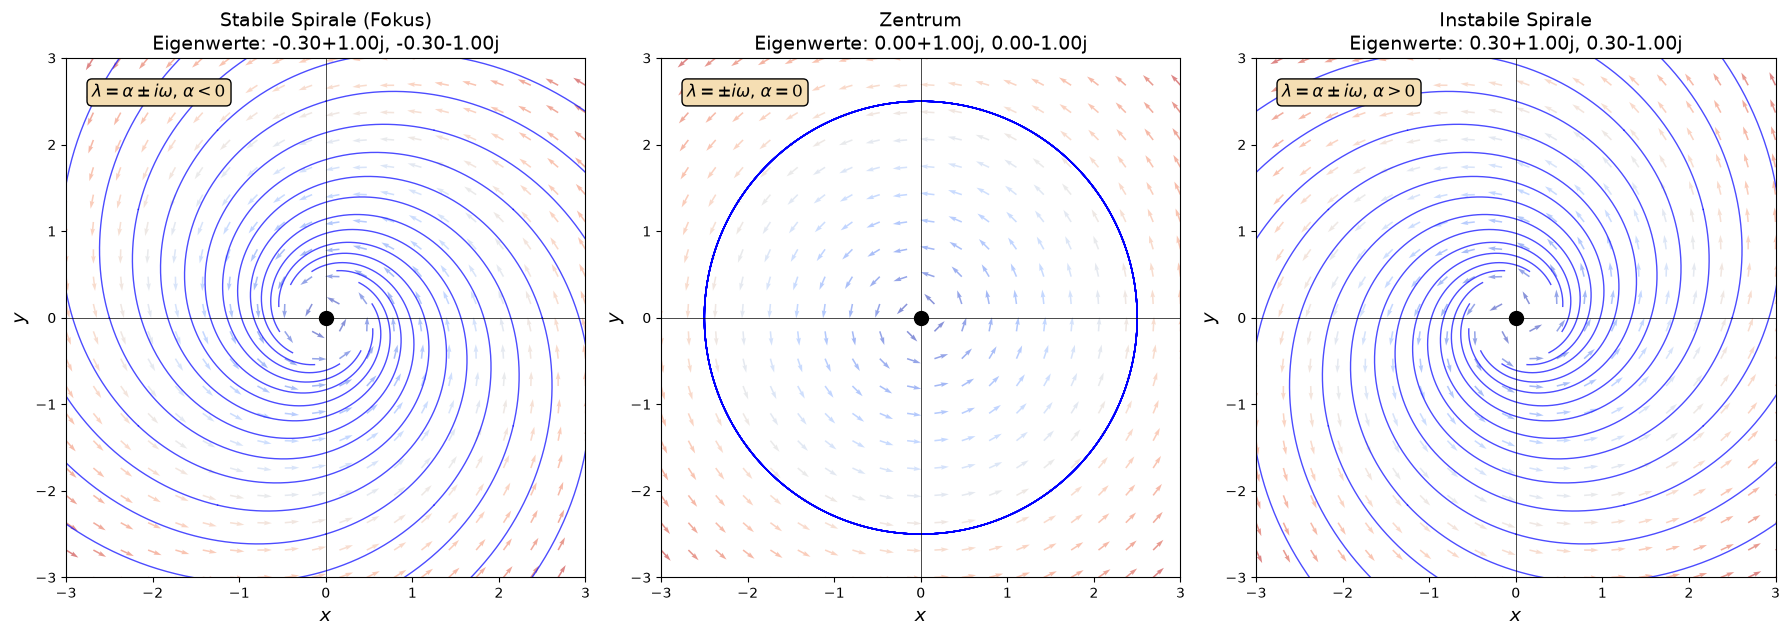

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# Stabile Spirale: λ = -0.3 ± i
A_stable_spiral = np.array([[-0.3, -1], [1, -0.3]])
plot_linear_system(A_stable_spiral, title='Stabile Spirale (Fokus)', ax=axes[0])
axes[0].text(0.05, 0.95, r'$\lambda = \alpha \pm i\omega$, $\alpha < 0$', 
            transform=axes[0].transAxes, fontsize=12, verticalalignment='top',
            bbox=dict(boxstyle='round', facecolor='wheat'))

# Zentrum: λ = ±i (rein imaginär)
A_center = np.array([[0, -1], [1, 0]])
plot_linear_system(A_center, title='Zentrum', ax=axes[1])
axes[1].text(0.05, 0.95, r'$\lambda = \pm i\omega$, $\alpha = 0$',
            transform=axes[1].transAxes, fontsize=12, verticalalignment='top',
            bbox=dict(boxstyle='round', facecolor='wheat'))

# Instabile Spirale: λ = 0.3 ± i
A_unstable_spiral = np.array([[0.3, -1], [1, 0.3]])
plot_linear_system(A_unstable_spiral, title='Instabile Spirale', ax=axes[2])
axes[2].text(0.05, 0.95, r'$\lambda = \alpha \pm i\omega$, $\alpha > 0$',
            transform=axes[2].transAxes, fontsize=12, verticalalignment='top',
            bbox=dict(boxstyle='round', facecolor='wheat'))

plt.tight_layout()
plt.show()

### Komplexe Eigenwerte: Die Bedeutung

Wenn $\lambda = \alpha \pm i\omega$:

- $\omega$ bestimmt die **Rotationsfrequenz** (Schwingung)
- $\alpha$ bestimmt, ob die Spirale **einwärts** ($\alpha < 0$) oder **auswärts** ($\alpha > 0$) geht
- $\alpha = 0$: **Zentrum** - geschlossene Ellipsen, keine Annäherung oder Flucht

Das **Zentrum** ist besonders: Es ist **strukturell instabil**. Die kleinste Störung (z.B. etwas Dämpfung) macht aus dem Zentrum eine Spirale. Im nichtlinearen Fall kann ein linearisiertes Zentrum zu einer Spirale werden - hier versagt die Linearisierung.

---

## 3.3 Die Klassifikation: Das große Bild

Alle Fälle lassen sich elegant durch zwei Größen parametrisieren:

- **Spur:** $\tau = \text{tr}(A) = \lambda_1 + \lambda_2$
- **Determinante:** $\Delta = \det(A) = \lambda_1 \cdot \lambda_2$

Die Eigenwerte sind:
$$\lambda_{1,2} = \frac{\tau \pm \sqrt{\tau^2 - 4\Delta}}{2}$$

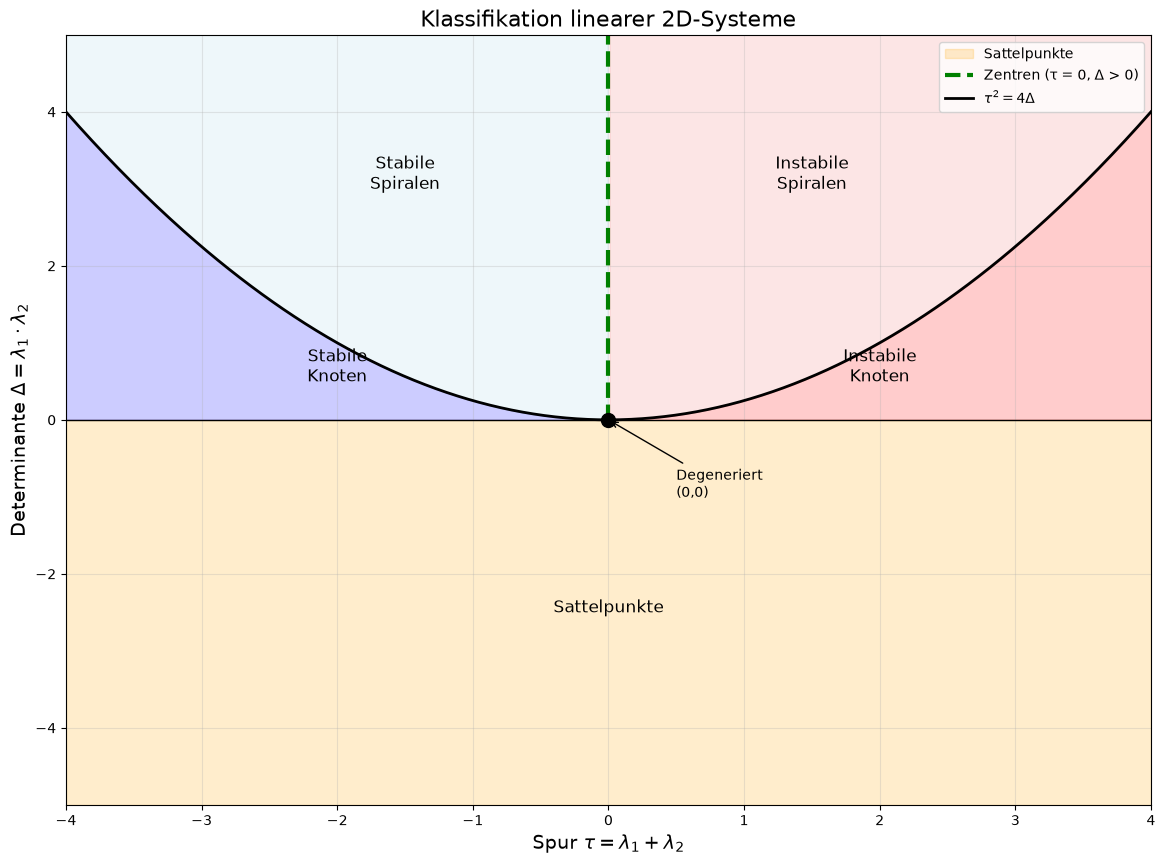

In [6]:
def plot_classification_diagram():
    """
    Das berühmte τ-Δ Klassifikationsdiagramm.
    """
    fig, ax = plt.subplots(figsize=(14, 10))
    
    # Achsen
    tau = np.linspace(-4, 4, 500)
    
    # Die Parabel τ² = 4Δ (Grenze zwischen Knoten und Spiralen)
    delta_parabola = tau**2 / 4
    
    # Regionen einfärben
    # Sättel: Δ < 0
    ax.fill_between(tau, -5, 0, alpha=0.2, color='orange', label='Sattelpunkte')
    
    # Instabile Knoten: Δ > 0, τ > 0, τ² > 4Δ
    ax.fill_between(tau[tau > 0], delta_parabola[tau > 0], 0, 
                    where=(delta_parabola[tau > 0] > 0), alpha=0.2, color='red')
    
    # Stabile Knoten: Δ > 0, τ < 0, τ² > 4Δ
    ax.fill_between(tau[tau < 0], delta_parabola[tau < 0], 0,
                    where=(delta_parabola[tau < 0] > 0), alpha=0.2, color='blue')
    
    # Instabile Spiralen: τ² < 4Δ, τ > 0
    ax.fill_between(tau[tau > 0], delta_parabola[tau > 0], 5,
                    alpha=0.2, color='lightcoral')
    
    # Stabile Spiralen: τ² < 4Δ, τ < 0
    ax.fill_between(tau[tau < 0], delta_parabola[tau < 0], 5,
                    alpha=0.2, color='lightblue')
    
    # Zentren: τ = 0, Δ > 0
    ax.plot([0, 0], [0, 5], color='green', linewidth=3, linestyle='--',
            label='Zentren (τ = 0, Δ > 0)')
    
    # Parabel
    ax.plot(tau, delta_parabola, 'k-', linewidth=2, label=r'$\tau^2 = 4\Delta$')
    
    # Δ = 0 Linie
    ax.axhline(y=0, color='black', linewidth=1)
    
    # Labels
    ax.text(2, 0.5, 'Instabile\nKnoten', fontsize=12, ha='center')
    ax.text(-2, 0.5, 'Stabile\nKnoten', fontsize=12, ha='center')
    ax.text(1.5, 3, 'Instabile\nSpiralen', fontsize=12, ha='center')
    ax.text(-1.5, 3, 'Stabile\nSpiralen', fontsize=12, ha='center')
    ax.text(0, -2.5, 'Sattelpunkte', fontsize=12, ha='center')
    
    # Degenerate Fälle
    ax.plot(0, 0, 'ko', markersize=10)
    ax.annotate('Degeneriert\n(0,0)', xy=(0, 0), xytext=(0.5, -1),
               fontsize=10, arrowprops=dict(arrowstyle='->'))
    
    ax.set_xlabel(r'Spur $\tau = \lambda_1 + \lambda_2$', fontsize=14)
    ax.set_ylabel(r'Determinante $\Delta = \lambda_1 \cdot \lambda_2$', fontsize=14)
    ax.set_title('Klassifikation linearer 2D-Systeme', fontsize=16)
    ax.set_xlim(-4, 4)
    ax.set_ylim(-5, 5)
    ax.legend(loc='upper right')
    ax.grid(True, alpha=0.3)
    
    return fig

plot_classification_diagram()
plt.show()

### Das Klassifikationsdiagramm: Dein Kompass

Für jede $2 \times 2$ Matrix $A$:
1. Berechne $\tau = a + d$ (Spur)
2. Berechne $\Delta = ad - bc$ (Determinante)
3. Finde den Punkt $(\tau, \Delta)$ im Diagramm
4. Lies den Typ des Fixpunkts ab

**Grenzfälle:**
- **$\Delta = 0$:** Mindestens ein Eigenwert ist 0 → degeneriert
- **$\tau = 0$, $\Delta > 0$:** Rein imaginäre Eigenwerte → Zentrum
- **$\tau^2 = 4\Delta$:** Doppelter Eigenwert → Sternknoten oder degenerierter Knoten

---

## 3.4 Die Nullklinen-Methode: Qualitative Analyse ohne Rechnung

Für beliebige (auch nichtlineare!) 2D-Systeme:

$$\dot{x} = f(x, y)$$
$$\dot{y} = g(x, y)$$

**Definition:**
- **x-Nullkline:** Menge aller $(x, y)$ wo $f(x, y) = 0$ → dort ist $\dot{x} = 0$ (vertikale Bewegung!)
- **y-Nullkline:** Menge aller $(x, y)$ wo $g(x, y) = 0$ → dort ist $\dot{y} = 0$ (horizontale Bewegung!)

**Schnittpunkte der Nullklinen = Fixpunkte!**

In [7]:
def plot_nullclines_and_flow(f, g, x_range, y_range, title=""):
    """
    Visualisiert Nullklinen und das Vektorfeld.
    """
    fig, ax = plt.subplots(figsize=(12, 10))
    
    # Gitter für Nullklinen
    x = np.linspace(x_range[0], x_range[1], 500)
    y = np.linspace(y_range[0], y_range[1], 500)
    X, Y = np.meshgrid(x, y)
    
    # Berechne f und g auf dem Gitter
    F = np.zeros_like(X)
    G = np.zeros_like(Y)
    for i in range(len(x)):
        for j in range(len(y)):
            F[j, i] = f(X[j, i], Y[j, i])
            G[j, i] = g(X[j, i], Y[j, i])
    
    # Nullklinen als Konturen
    ax.contour(X, Y, F, levels=[0], colors='blue', linewidths=2.5, linestyles='-')
    ax.contour(X, Y, G, levels=[0], colors='red', linewidths=2.5, linestyles='-')
    
    # Vektorfeld (gröber)
    x_v = np.linspace(x_range[0], x_range[1], 20)
    y_v = np.linspace(y_range[0], y_range[1], 20)
    X_v, Y_v = np.meshgrid(x_v, y_v)
    
    U = np.zeros_like(X_v)
    V = np.zeros_like(Y_v)
    for i in range(len(x_v)):
        for j in range(len(y_v)):
            U[j, i] = f(X_v[j, i], Y_v[j, i])
            V[j, i] = g(X_v[j, i], Y_v[j, i])
    
    M = np.sqrt(U**2 + V**2)
    M[M == 0] = 1
    ax.quiver(X_v, Y_v, U/M, V/M, M, cmap='Greys', alpha=0.5)
    
    # Legende
    ax.plot([], [], 'b-', linewidth=2.5, label=r'x-Nullkline: $\dot{x} = 0$')
    ax.plot([], [], 'r-', linewidth=2.5, label=r'y-Nullkline: $\dot{y} = 0$')
    
    ax.set_xlabel(r'$x$', fontsize=14)
    ax.set_ylabel(r'$y$', fontsize=14)
    ax.set_title(title, fontsize=16)
    ax.legend(loc='upper right')
    ax.set_xlim(x_range)
    ax.set_ylim(y_range)
    ax.set_aspect('equal')
    
    return fig, ax

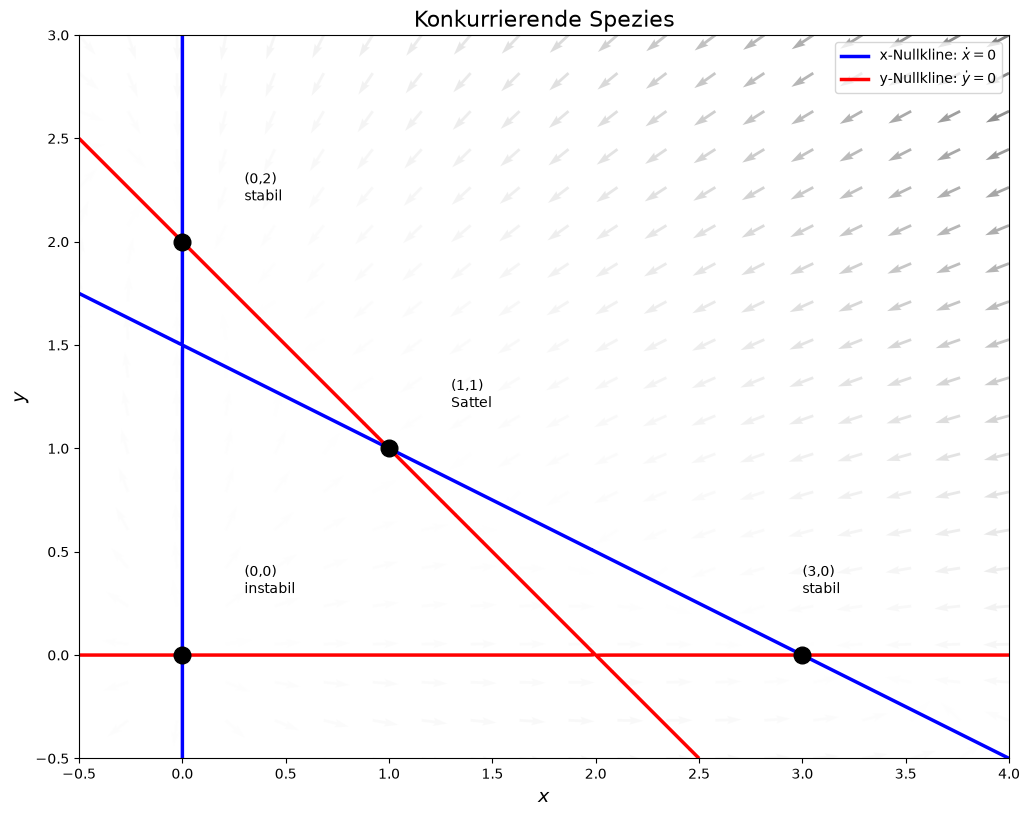

In [8]:
# Beispiel: Konkurrenz zweier Spezies
# ẋ = x(3 - x - 2y)   [Spezies 1]
# ẏ = y(2 - x - y)    [Spezies 2]

def f_comp(x, y):
    return x * (3 - x - 2*y)

def g_comp(x, y):
    return y * (2 - x - y)

fig, ax = plot_nullclines_and_flow(f_comp, g_comp, (-0.5, 4), (-0.5, 3),
                                    title='Konkurrierende Spezies')

# Markiere Fixpunkte manuell
fixed_points = [(0, 0), (3, 0), (0, 2), (1, 1)]
for fp in fixed_points:
    ax.plot(fp[0], fp[1], 'ko', markersize=12)

ax.annotate('(0,0)\ninstabil', xy=(0, 0), xytext=(0.3, 0.3), fontsize=10)
ax.annotate('(3,0)\nstabil', xy=(3, 0), xytext=(3, 0.3), fontsize=10)
ax.annotate('(0,2)\nstabil', xy=(0, 2), xytext=(0.3, 2.2), fontsize=10)
ax.annotate('(1,1)\nSattel', xy=(1, 1), xytext=(1.3, 1.2), fontsize=10)

plt.show()

### Die Macht der Nullklinen

Beobachte, wie die Nullklinen den Phasenraum strukturieren:

- **Auf der x-Nullkline** (blau): Vektoren zeigen vertikal (↑ oder ↓)
- **Auf der y-Nullkline** (rot): Vektoren zeigen horizontal (← oder →)
- **In den Regionen dazwischen**: Kombination, z.B. ↗ ↘ ↙ ↖

Du kannst die Flussrichtung in jeder Region **ohne Rechnung** bestimmen, indem du einfach das Vorzeichen von $f$ und $g$ prüfst!

---

## 3.5 Ein klassisches Beispiel: Das Lotka-Volterra Räuber-Beute System

$$\dot{x} = x(\alpha - \beta y)$$
$$\dot{y} = y(-\gamma + \delta x)$$

Wobei:
- $x$: Beutepopulation
- $y$: Räuberpopulation
- $\alpha$: Wachstumsrate der Beute
- $\beta$: Fressrate der Räuber
- $\gamma$: Sterberate der Räuber
- $\delta$: Effizienz der Umwandlung von Beute in Räuber

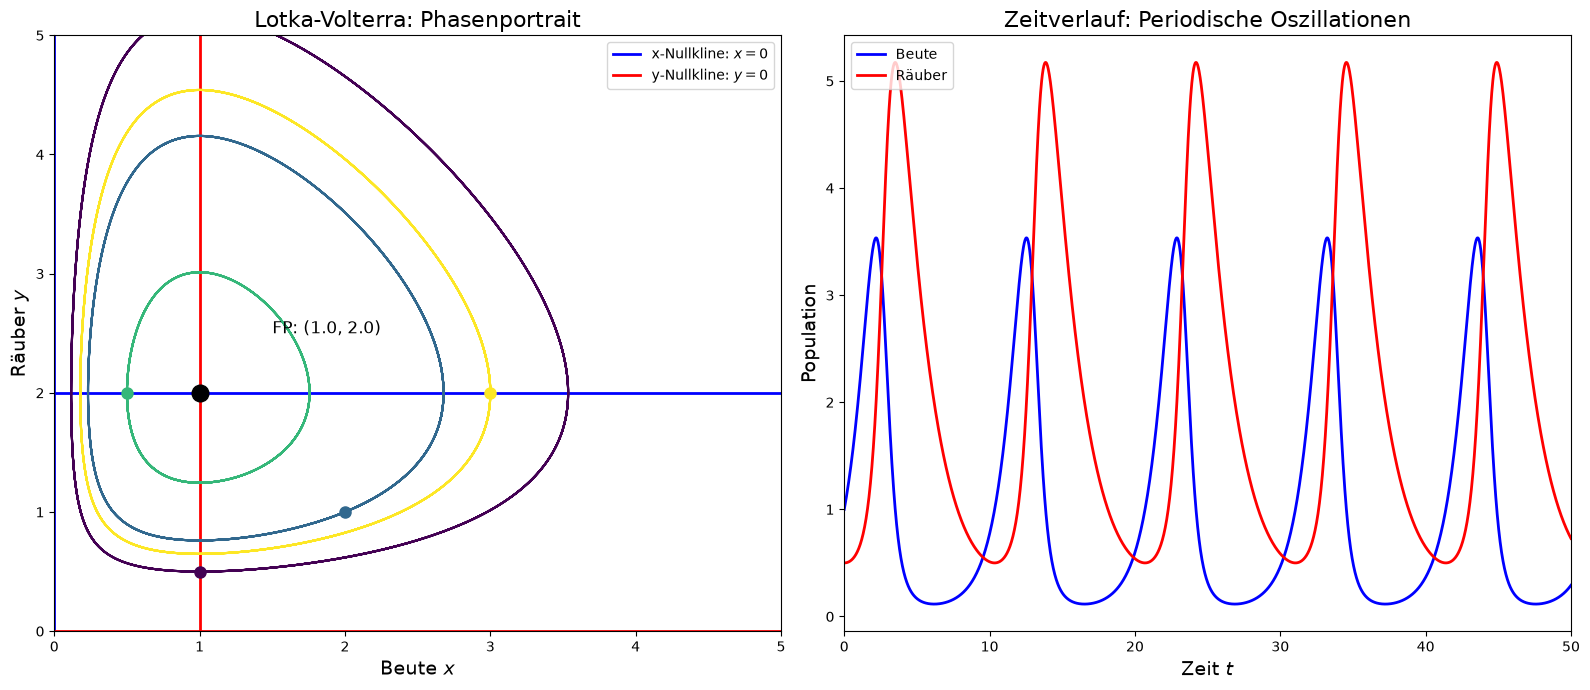

In [9]:
# Lotka-Volterra mit Standardparametern
alpha, beta, gamma, delta = 1.0, 0.5, 0.5, 0.5

def lotka_volterra(state, t):
    x, y = state
    return [x * (alpha - beta * y),
            y * (-gamma + delta * x)]

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Phasenportrait
ax1 = axes[0]

# Nullklinen
y_range = np.linspace(0.01, 5, 100)
x_range = np.linspace(0.01, 5, 100)

ax1.axvline(x=0, color='blue', linewidth=2, label=r'x-Nullkline: $x=0$')
ax1.axhline(y=alpha/beta, color='blue', linewidth=2)
ax1.axhline(y=0, color='red', linewidth=2, label=r'y-Nullkline: $y=0$')
ax1.axvline(x=gamma/delta, color='red', linewidth=2)

# Fixpunkt
x_star, y_star = gamma/delta, alpha/beta
ax1.plot(x_star, y_star, 'ko', markersize=12)
ax1.annotate(f'FP: ({x_star:.1f}, {y_star:.1f})', xy=(x_star, y_star),
            xytext=(x_star+0.5, y_star+0.5), fontsize=12)

# Trajektorien
t = np.linspace(0, 50, 2000)
initial_conditions = [[1, 0.5], [2, 1], [0.5, 2], [3, 2]]
colors = plt.cm.viridis(np.linspace(0, 1, len(initial_conditions)))

for ic, color in zip(initial_conditions, colors):
    sol = odeint(lotka_volterra, ic, t)
    ax1.plot(sol[:, 0], sol[:, 1], color=color, linewidth=1.5)
    ax1.plot(ic[0], ic[1], 'o', color=color, markersize=8)

ax1.set_xlabel(r'Beute $x$', fontsize=14)
ax1.set_ylabel(r'Räuber $y$', fontsize=14)
ax1.set_title('Lotka-Volterra: Phasenportrait', fontsize=16)
ax1.set_xlim(0, 5)
ax1.set_ylim(0, 5)
ax1.legend(loc='upper right')

# Zeitverlauf
ax2 = axes[1]
sol = odeint(lotka_volterra, [1, 0.5], t)
ax2.plot(t, sol[:, 0], 'b-', linewidth=2, label='Beute')
ax2.plot(t, sol[:, 1], 'r-', linewidth=2, label='Räuber')
ax2.set_xlabel(r'Zeit $t$', fontsize=14)
ax2.set_ylabel('Population', fontsize=14)
ax2.set_title('Zeitverlauf: Periodische Oszillationen', fontsize=16)
ax2.legend()
ax2.set_xlim(0, 50)

plt.tight_layout()
plt.show()

### Beobachtungen

Das Lotka-Volterra System zeigt ein **Zentrum**: Geschlossene Orbits um den Fixpunkt.

- Beute und Räuber oszillieren **aus der Phase**: Wenn Beute zunimmt, folgen die Räuber mit Verzögerung
- Die Amplitude hängt von der Anfangsbedingung ab (keine Konvergenz zu einer festen Amplitude)
- Der Fixpunkt $(\gamma/\delta, \alpha/\beta)$ ist ein Zentrum - **strukturell instabil**

In der Realität führt jede kleine Störung (Saisonalität, Umweltrauschen) zu qualitativen Änderungen. Das ist eine Schwäche des einfachen Lotka-Volterra Modells.

---

## 3.6 Zusammenfassung

### Kernkonzepte

1. **Eigenwert-Klassifikation**: Die Eigenwerte der Jacobi-Matrix bestimmen den Typ des Fixpunkts
   - Reell, gleiches Vorzeichen → Knoten
   - Reell, verschiedenes Vorzeichen → Sattel
   - Komplex → Spirale oder Zentrum

2. **Spur-Determinanten-Diagramm**: Schnelle Klassifikation via $\tau$ und $\Delta$

3. **Nullklinen**: Strukturieren den Phasenraum, Schnittpunkte = Fixpunkte

4. **Mannigfaltigkeiten**: Stabile/instabile Mannigfaltigkeiten von Sattelpunkten sind die "Skelettstruktur" des Phasenraums

### Was kommt

Im nächsten Modul: **Nichtlineare Systeme**
- Linearisierung um Fixpunkte (Hartman-Grobman)
- Grenzzyklen - ein Phänomen, das es nur nichtlinear gibt
- Warum auch in 2D kein Chaos möglich ist (Poincaré-Bendixson)

---

## Übungen

### Übung 3.1
Klassifiziere den Fixpunkt des Systems:
$$\dot{x} = 2x - y$$
$$\dot{y} = x + 2y$$

### Übung 3.2
Für das System $\dot{x} = -x + xy$, $\dot{y} = y - xy$:
- Finde alle Fixpunkte
- Bestimme Stabilität durch Linearisierung
- Zeichne die Nullklinen

### Übung 3.3 (Konzeptuell)
Warum ist ein Zentrum "strukturell instabil"? Was bedeutet das physikalisch?

In [10]:
# Raum für deine Lösungen

